Tutorial Code by **Amirhossein Ahrari**
YouTube: https://www.youtube.com/@amirhosseinahrarigee

**Tutorial Video:** Google Earth Engine Tutorial-216: Mangrove Change Detection and Monitoring in Python

This code is part of a tutorial series on Earth Engine programming techniques
presented on the Amirhossein Ahrari YouTube channel. You are free to use and modify
this code for academic and non-academic purposes. Don't forget to subscribe to
the Amirhossein Ahrari channel and follow the videos to support the instructor

# **Connect to GEE**

In [1]:
!pip install -q --upgrade --pre xee
!pip install -q -U geemap

In [2]:
import ee

In [3]:
ee.Authenticate()
ee.Initialize(
    project = 'ee-amirhosseinahrari',
    opt_url = 'https://earthengine-highvolume.googleapis.com'
)

# **Study Area**

In [4]:
import geemap

In [5]:
map = geemap.Map(basemap = 'SATELLITE')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [6]:
roi = map.draw_last_feature.geometry()
roi

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Polygon",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      [
                        [
                          55.605927,
                          26.762778
                        ],
                        [
                          55.605927,
                          26.923907
                        ],
                        [
                          55.789261,
                          26.923907
                        ],
                        [
                          55.789261,
                          26.762778
                        ],
                        [
                          55.605927,
                          26.762778
                        ]
                      ]
                    ]
                  },
                  "geodesic": {
                    "constantValue": false
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

# **Mangrove Image Collection**

In [10]:
mang = (
    ee.ImageCollection("projects/mangrovedatahub2/assets/CGMD-AFCC30")
    .filterBounds(roi)
    .filter(ee.Filter.eq('tile_id','MiddleEast'))
)

In [11]:
mang.size()

In [ ]:
mang

# **to Xarray**

In [13]:
from xee import helpers
from shapely.geometry import shape
import xarray as xr

In [15]:
mang.first().select('FCC').projection()

In [16]:
grid = helpers.fit_geometry(
    geometry = shape(roi.getInfo()),
    grid_crs = 'EPSG:3857',
    grid_scale = (30, -30)
)

In [17]:
ds = xr.open_dataset(
    mang,
    engine = 'ee',
    **grid
)

In [19]:
ds = ds.sortby('time') * 1

# **Image Preview**

In [22]:
ds_mean = ds.mean(dim = 'time')

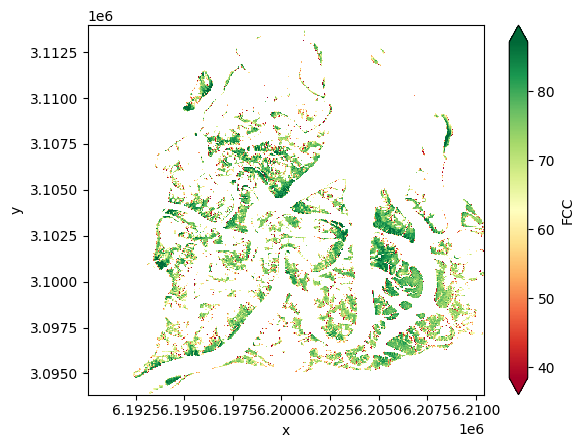

In [24]:
ds_mean['FCC'].plot(robust = True, cmap = 'RdYlGn')

# **Temporal Monitoring**

In [27]:
df = ds.mean(dim = ['x','y']).to_dataframe()

In [28]:
import matplotlib.pyplot as plt

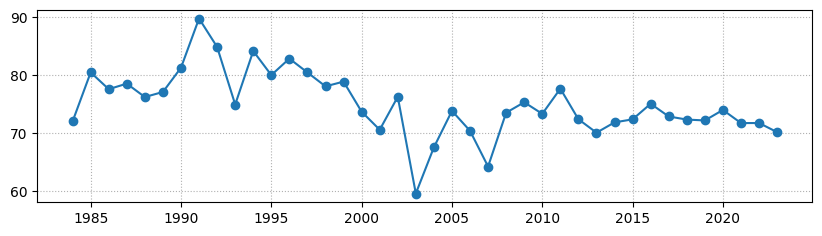

In [34]:
fig, ax = plt.subplots(figsize = (10, 2.5))

ax.plot(df.index, df, marker = 'o')
ax.grid(ls = ':')

# **Trend Analysis**

In [35]:
!pip install -q pymannkendall

In [37]:
import pymannkendall as mk

In [38]:
mang_trend = mk.original_test(df)

In [40]:
mang_trend

Mann_Kendall_Test(trend='decreasing', h=np.True_, p=np.float64(8.622720154738417e-05), z=np.float64(-3.9263986469590204), Tau=np.float64(-0.43333333333333335), s=np.float64(-338.0), var_s=7366.666666666667, slope=np.float64(-0.2325538604978531), intercept=np.float64(78.44048188981556))

# **Spatio - Temporal Trend Analysis**

In [41]:
import numpy as np

In [44]:
def mk_xr(ds_arr):
  mask = np.isfinite(ds_arr)
  ds_mask = ds_arr[mask]
  if len(ds_mask) <= 3:
    return np.nan, np.nan, np.nan
  ds_test = mk.original_test(ds_mask)
  return ds_test.slope, ds_test.p, ds_test.z


slope_map, p_map, z_map = xr.apply_ufunc(
    mk_xr,
    ds['FCC'],
    input_core_dims = [['time']],
    output_core_dims = [[],[],[]],
    dask = 'parallelized',
    vectorize= True,
    output_dtypes = [float, float, float]
)

In [45]:
slope_map = slope_map.where(p_map < 0.05)
z_map = z_map.where(p_map < 0.05)

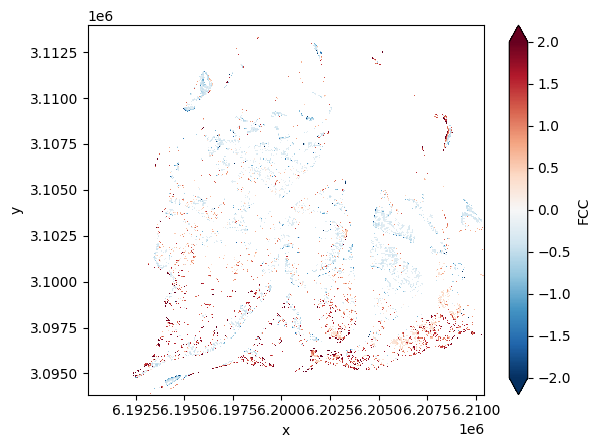

In [46]:
slope_map.plot(robust = True)

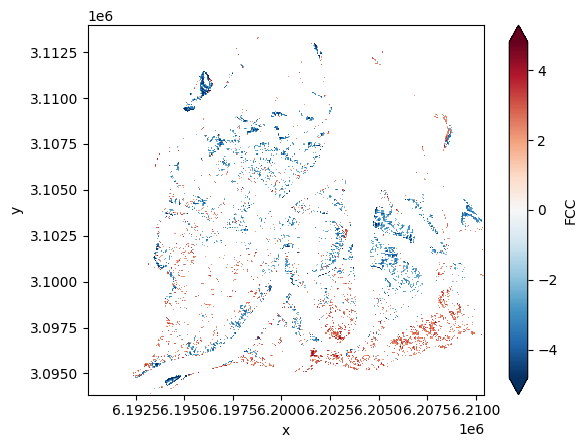

In [47]:
z_map.plot(robust = True)